# Prelude

In [1]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [2]:
seaborn.set()

# Getting Data

In [3]:
data = pandas.read_csv(
    'results/SAT_120s.csv',
    index_col = ['problem', 'strategy'],
)

In [4]:
strategies = data.index.get_level_values('strategy').unique()

In [5]:
strategies

Index(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveLiteral'], dtype='object', name='strategy')

# Analysing

In [6]:
control = ['FirstAction', 'LeanCopCut']

In [7]:
data[data.solved]

status  solved  steps  time_ms     info error
problem    strategy                                                      
AGT001+1.p FirstAction      solved    True    4.0      2.0  Theorem   NaN
           LeanCopCut       solved    True    4.0      2.0  Theorem   NaN
AGT001+2.p FirstAction      solved    True    4.0      2.0  Theorem   NaN
           LeanCopCut       solved    True    4.0      2.0  Theorem   NaN
AGT002+2.p FirstAction      solved    True  158.0   2731.0  Theorem   NaN
...                            ...     ...    ...      ...      ...   ...
TOP021+1.p LeanCopCut       solved    True    8.0      1.0  Theorem   NaN
           SATSolveLiteral  solved    True   32.0      7.0  Theorem   NaN
TOP022+1.p FirstAction      solved    True  309.0    151.0  Theorem   NaN
           LeanCopCut       solved    True  254.0    147.0  Theorem   NaN
TOP047+1.p SATSolveLiteral  solved    True  288.0  84233.0  Theorem   NaN

[5006 rows x 6 columns]

In [8]:
data[data.solved].groupby(level = 1).size()

strategy
FirstAction        1179
LeanCopCut         1216
SATSolve            211
SATSolveLiteral    2400
dtype: int64

In [9]:
solved = data['solved'].unstack('strategy')

In [10]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction          22
LeanCopCut           44
SATSolve             13
SATSolveLiteral    1754
dtype: int64

# Results

<Axes: xlabel='strategy'>

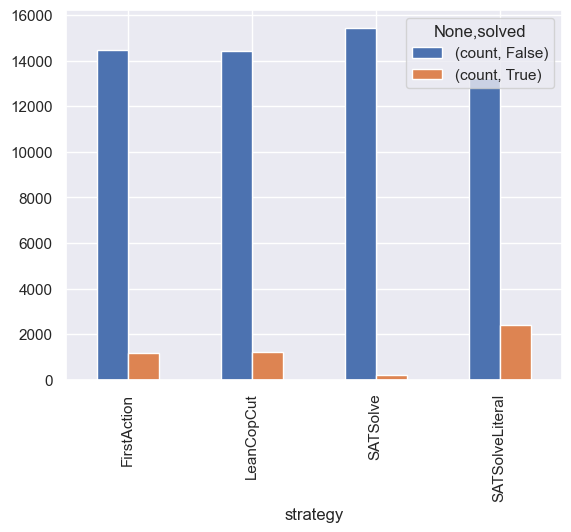

In [11]:
data.groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

<Axes: xlabel='winner', ylabel='loser'>

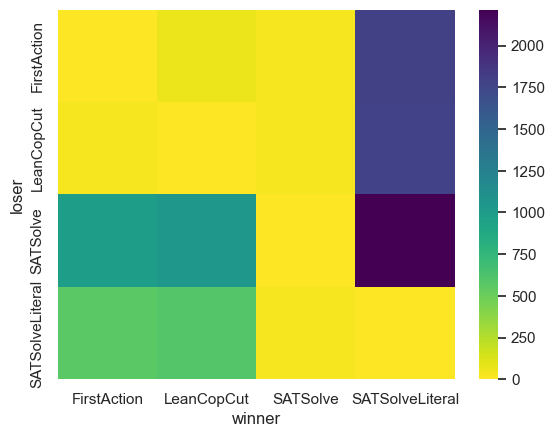

In [12]:
merged = pandas.merge(
    data.reset_index('strategy'),
    data.reset_index('strategy'),
    left_index = True,
    right_index = True,
    suffixes = ('_left', '_right'),
).set_index(['strategy_left', 'strategy_right'], append = True)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    .reset_index(['strategy_left', 'strategy_right'])
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [73]:
tr = {}
for problem in merged.index.get_level_values('problem').unique():
    base = problem[0:3]
    a = open(f'/home/mfixman/TP/TPTP/Problems/{base}/{problem}').readlines(100000)
    tr[problem] = sum(1 for x in a if x and not x.isspace() and x[0] != '%')

tr = Series(tr, name = 'length')
tr.index.name = 'problem'

In [74]:
tr

problem
AGT001+1.p      6
AGT001+2.p      7
AGT002+1.p      6
AGT002+2.p      7
AGT003+1.p      6
             ... 
TOP049-1.p     28
TOP050-1.p     70
TOP051-1.p     28
TOP052-1.p    290
TOP053-1.p     38
Name: length, Length: 15641, dtype: int64

In [98]:
merged.xs('SYN344-1.p')

status_left  solved_left  steps_left  \
strategy_left   strategy_right                                         
FirstAction     FirstAction         timeout        False         NaN   
                LeanCopCut          timeout        False         NaN   
                SATSolve            timeout        False         NaN   
                SATSolveLiteral     timeout        False         NaN   
LeanCopCut      FirstAction         timeout        False         NaN   
                LeanCopCut          timeout        False         NaN   
                SATSolve            timeout        False         NaN   
                SATSolveLiteral     timeout        False         NaN   
SATSolve        FirstAction         timeout        False         NaN   
                LeanCopCut          timeout        False         NaN   
                SATSolve            timeout        False         NaN   
                SATSolveLiteral     timeout        False         NaN   
SATSolveLiteral FirstAction          solved         True         5.0   
                LeanCopCut           solved         True         5.0   
                SATSolve             solved         True         5.0   
                SATSolveLiteral      solved         True         5.0   

                                 time_ms_left info_left error_left  \
strategy_left   strategy_right                                       
FirstAction     FirstAction               NaN       NaN        NaN   
                LeanCopCut                NaN       NaN        NaN   
                SATSolve                  NaN       NaN        NaN   
                SATSolveLiteral           NaN       NaN        NaN   
LeanCopCut      FirstAction               NaN       NaN        NaN   
                LeanCopCut                NaN       NaN        NaN   
                SATSolve                  NaN       NaN        NaN   
                SATSolveLiteral           NaN       NaN        NaN   
SATSolve        FirstAction               NaN       NaN        NaN   
                LeanCopCut                NaN       NaN        NaN   
                SATSolve                  NaN       NaN        NaN   
                SATSolveLiteral           NaN       NaN        NaN   
SATSolveLiteral FirstAction               1.0   Theorem        NaN   
                LeanCopCut                1.0   Theorem        NaN   
                SATSolve                  1.0   Theorem        NaN   
                SATSolveLiteral           1.0   Theorem        NaN   

                                status_right  solved_right  steps_right  \
strategy_left   strategy_right                                            
FirstAction     FirstAction          timeout         False          NaN   
                LeanCopCut           timeout         False          NaN   
                SATSolve             timeout         False          NaN   
                SATSolveLiteral       solved          True          5.0   
LeanCopCut      FirstAction          timeout         False          NaN   
                LeanCopCut           timeout         False          NaN   
                SATSolve             timeout         False          NaN   
                SATSolveLiteral       solved          True          5.0   
SATSolve        FirstAction          timeout         False          NaN   
                LeanCopCut           timeout         False          NaN   
                SATSolve             timeout         False          NaN   
                SATSolveLiteral       solved          True          5.0   
SATSolveLiteral FirstAction          timeout         False          NaN   
                LeanCopCut           timeout         False          NaN   
                SATSolve             timeout         False          NaN   
                SATSolveLiteral       solved          True          5.0   

                                 time_ms_right info_right error_right  
strategy_left   strategy_right                     

In [99]:
statistics = (
    merged
    .xs('SATSolveLiteral', level = 'strategy_right')
    .loc[lambda x: ~x.solved_left & x.solved_right]
    .loc[lambda x: x.index.get_level_values('problem').str.contains('-')]
    .groupby(level = 'problem')
    .filter(lambda x: len(x) == 3)
    .join(tr)
    .sort_values(['steps_right', 'length'], kind = 'stable')
)
statistics.xs('SYN344-1.p')

,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,status_right,solved_right,steps_right,time_ms_right,info_right,error_right,length
strategy_left,,,,,,,,,,,,,
FirstAction,timeout,False,NaN,NaN,NaN,NaN,solved,True,5.0,1.0,Theorem,NaN,15
LeanCopCut,timeout,False,NaN,NaN,NaN,NaN,solved,True,5.0,1.0,Theorem,NaN,15
SATSolve,timeout,False,NaN,NaN,NaN,NaN,solved,True,5.0,1.0,Theorem,NaN,15


# 

In [45]:
pandas.Series(tr)

SET851-2.p     19
SWV302-2.p     22
SYN344-1.p     15
MGT039-2.p    119
ANA044-2.p     23
             ... 
GRP371-1.p    167
GRP017-1.p     11
GRP039-5.p     24
NLP008-1.p    209
NLP007-1.p    220
Length: 1033, dtype: int64